# 第 1 章 初识蒙特卡罗方法 — 代码实验

对照教材：Dunn & Shultis《Exploring Monte Carlo Methods》Ch.1；Shonkwiler & Mendivil《Explorations in Monte Carlo Methods》§1.1、§1.4。

约定：随机种子 2024；所有插图保存到 `docs/mc/images/ch01/`，编号 `out-1-M` 与笔记图注一一对应。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch01")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2024)   # 全章共用一个随机数流
print("numpy", np.__version__)

numpy 2.4.6


## 实验 1 用频率估计概率（§1.1）

抛硬币：$u\sim U(0,1)$，$u<0.5$ 记"正面"。看频率 $S/N$ 怎么随 $N$ 稳定到 $0.5$，以及误差是不是按 $N^{-1/2}$ 下降。

In [2]:
N = 100_000
flips = rng.random(N) < 0.5
freq = np.cumsum(flips) / np.arange(1, N + 1)
print(f"N=100    频率 = {freq[99]:.4f}")
print(f"N=10^5   频率 = {freq[-1]:.4f}")

N=100    频率 = 0.6300
N=10^5   频率 = 0.5009


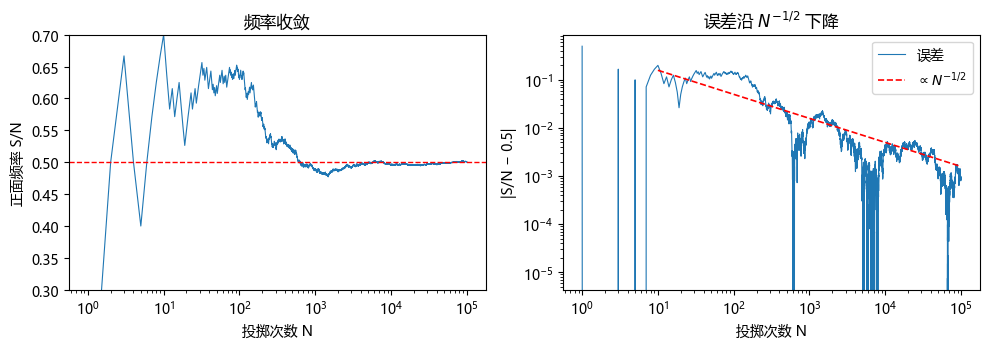

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(np.arange(1, N + 1), freq, lw=0.8)
ax[0].axhline(0.5, color="r", ls="--", lw=1)
ax[0].set_xscale("log"); ax[0].set_ylim(0.3, 0.7)
ax[0].set_xlabel("投掷次数 N"); ax[0].set_ylabel("正面频率 S/N")
ax[0].set_title("频率收敛")
nn = np.logspace(1, 5, 200)
ax[1].loglog(np.arange(1, N + 1), np.abs(freq - 0.5), lw=0.8, label="误差")
ax[1].loglog(nn, 0.5 / np.sqrt(nn), "r--", lw=1.2, label=r"$\propto N^{-1/2}$")
ax[1].set_xlabel("投掷次数 N"); ax[1].set_ylabel("|S/N − 0.5|")
ax[1].legend(); ax[1].set_title("误差沿 $N^{-1/2}$ 下降")
fig.tight_layout(); save(fig, "out-1-1.png"); plt.show()

## 实验 2 蒲丰投针（§1.2）

$P_{cut}=2L/(\pi D)$ 的推导见笔记 §1.2。模拟判据（利用对称性折半）：中点到最近线距离 $d\sim U(0,D/2)$、夹角 $\theta\sim U(0,\pi/2)$，相交 $\iff d\le (L/2)\sin\theta$。

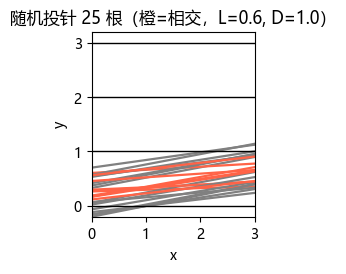

In [4]:
D, L = 1.0, 0.6
n_show = 25
d0  = rng.uniform(0, D/2, n_show)        # 中点高度
th0 = rng.uniform(0, np.pi/2, n_show)    # 夹角
side0 = rng.integers(0, 2, n_show)*2 - 1 # 中点在哪个半带
x0 = np.linspace(0, 3, 2)
fig, ax = plt.subplots(figsize=(7, 2.4))
for i in range(n_show):
    y = side0[i] * d0[i] + D/2
    hit = d0[i] <= (L/2) * np.sin(th0[i])
    ax.plot([x0[0], x0[1]], [y - (L/2)*np.cos(th0[i]), y + (L/2)*np.cos(th0[i])],
            color="tomato" if hit else "gray", lw=1.6)
for g in range(4):
    ax.axhline(g, color="k", lw=1)
ax.set_xlim(0, 3); ax.set_ylim(-0.2, 3.2); ax.set_aspect("equal")
ax.set_title(f"随机投针 {n_show} 根（橙=相交，L={L}, D={D}）")
ax.set_xlabel("x"); ax.set_ylabel("y")
save(fig, "out-1-2.png"); plt.show()

P_cut = 0.3821（理论 0.3820），pi ≈ 3.1402


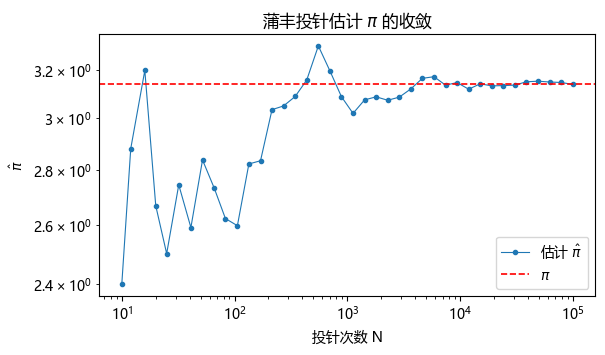

In [5]:
Nd = 100_000
d  = rng.uniform(0, D/2, Nd)
th = rng.uniform(0, np.pi/2, Nd)
hit = d <= (L/2) * np.sin(th)
p_hat = hit.mean()
pi_hat = 2 * L / (p_hat * D)
print(f"P_cut = {p_hat:.4f}（理论 {2*L/(np.pi*D):.4f}），pi ≈ {pi_hat:.4f}")
Ns = np.unique(np.logspace(1, 5, 40).astype(int))
pi_est = np.array([2*L/((d[:n] <= (L/2)*np.sin(th[:n])).mean()*D) for n in Ns])
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.loglog(Ns, pi_est, "o-", ms=3, lw=0.8, label=r"估计 $\hat\pi$")
ax.axhline(np.pi, color="r", ls="--", lw=1.2, label=r"$\pi$")
ax.set_xlabel("投针次数 N"); ax.set_ylabel(r"$\hat\pi$")
ax.legend(); ax.set_title(r"蒲丰投针估计 $\pi$ 的收敛")
save(fig, "out-1-3.png"); plt.show()

## 实验 3 求积视角：hit-or-miss 与平均值法（§1.4）

靶子：$I=\int_0^1 e^{-x^2}\,dx = 0.7468241\dots$（无初等原函数）。hit-or-miss 用 0/1 分数，平均值法用连续分数 $g(x_i)$。

hit-or-miss 估计 pi/4: 0.7855（真值 0.7854）, pi ≈ 3.1420


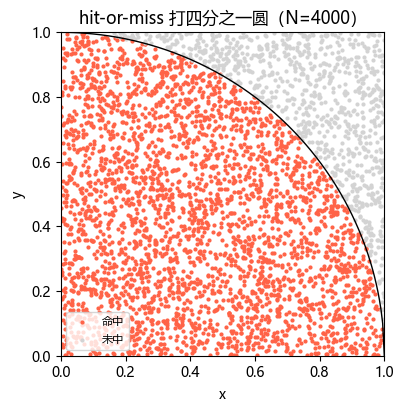

In [6]:
M = 4000
x, y = rng.random(M), rng.random(M)
inside = x**2 + y**2 <= 1
pi_hit = 4 * inside.mean()   # 四分之一圆面积 pi/4 的 hit-or-miss
print(f"hit-or-miss 估计 pi/4: {inside.mean():.4f}（真值 {np.pi/4:.4f}）, pi ≈ {pi_hit:.4f}")
fig, ax = plt.subplots(figsize=(4.2, 4.2))
ax.scatter(x[inside], y[inside], s=4, color="tomato", label="命中")
ax.scatter(x[~inside], y[~inside], s=4, color="lightgray", label="未中")
xx = np.linspace(0, 1, 200)
ax.plot(xx, np.sqrt(1 - xx*xx), "k-", lw=1)
ax.set_aspect("equal"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title(f"hit-or-miss 打四分之一圆（N={M}）"); ax.set_xlabel("x"); ax.set_ylabel("y")
ax.legend(loc="lower left", fontsize=8)
save(fig, "out-1-4.png"); plt.show()

N=100000: 投点法 = 0.74868, 平均值法 = 0.74610, 真值 = 0.74682


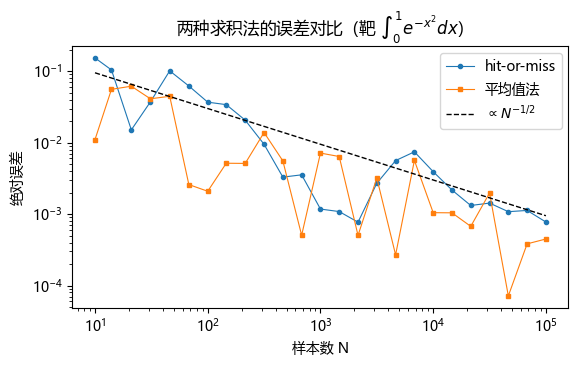

In [7]:
exact = 0.7468241328124271
Nq = 100_000
xx_, yy_ = rng.random(Nq), rng.random(Nq)
hm = (yy_ <= np.exp(-xx_*xx_)).mean()          # 投点法（容器面积 1）
mean_est = np.exp(-rng.random(Nq)**2).mean()   # 平均值法
print(f"N={Nq}: 投点法 = {hm:.5f}, 平均值法 = {mean_est:.5f}, 真值 = {exact:.5f}")
Ns2 = np.unique(np.logspace(1, 5, 25).astype(int))
err_hm, err_mean = [], []
for n in Ns2:
    a, b = rng.random(n), rng.random(n)
    err_hm.append(abs((b <= np.exp(-a*a)).mean() - exact))
    err_mean.append(abs(np.exp(-rng.random(n)**2).mean() - exact))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.loglog(Ns2, err_hm, "o-", ms=3, lw=0.8, label="hit-or-miss")
ax.loglog(Ns2, err_mean, "s-", ms=3, lw=0.8, label="平均值法")
ax.loglog(Ns2, 0.3/np.sqrt(Ns2), "k--", lw=1, label=r"$\propto N^{-1/2}$")
ax.set_xlabel("样本数 N"); ax.set_ylabel("绝对误差")
ax.legend(); ax.set_title("两种求积法的误差对比（靶 $\\int_0^1 e^{-x^2}dx$）")
save(fig, "out-1-5.png"); plt.show()

## 实验 4 直方图与样本路径（§1.5，S&M §1.1.2/1.1.3）

**super-experiment**：把 100 次投针打包成一个实验、估计 $1/\pi$，重复 2000 次并画直方图——钟形分布是第 2 章中心极限定理的预告。**样本路径**：赌徒每局 ±1 美元（50%），本金 100，庄家 2000，破产或通吃为止。

2000 个 super-experiment: 均值 0.3186（1/pi = 0.3183）, 样本标准差 0.0477


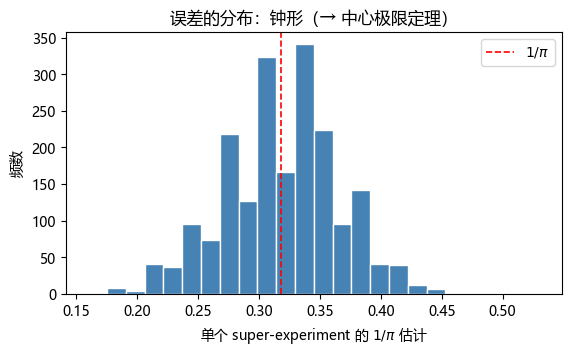

In [8]:
throws, reps = 100, 2000
D2, L2 = 2.0, 1.0   # 取 d = 2L 特例（S&M 的用法），此时 P_cut = 1/pi
y = np.empty(reps)
for i in range(reps):
    dd = rng.uniform(0, D2/2, throws)
    tt = rng.uniform(0, np.pi/2, throws)
    y[i] = (dd <= (L2/2)*np.sin(tt)).mean()   # 该 super-experiment 对 P_cut=1/pi 的估计
print(f"2000 个 super-experiment: 均值 {y.mean():.4f}（1/pi = {1/np.pi:.4f}）, 样本标准差 {y.std(ddof=1):.4f}")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(y, bins=24, color="steelblue", edgecolor="white")
ax.axvline(1/np.pi, color="r", ls="--", lw=1.2, label=r"$1/\pi$")
ax.set_xlabel(r"单个 super-experiment 的 $1/\pi$ 估计"); ax.set_ylabel("频数")
ax.legend(); ax.set_title("误差的分布：钟形（→ 中心极限定理）")
save(fig, "out-1-6.png"); plt.show()

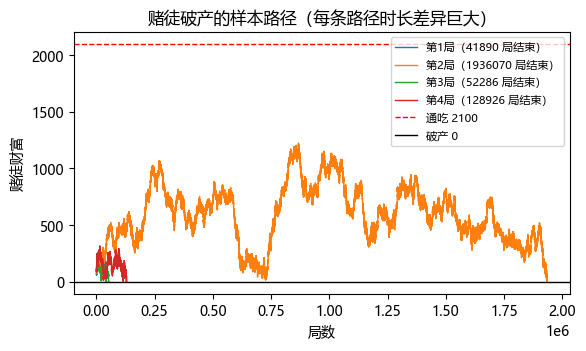

In [9]:
fig, ax = plt.subplots(figsize=(6.4, 3.4))
for k in range(4):
    R, i = [100], 0
    while 0 < R[i] < 2100:
        i += 1
        R.append(R[-1] + (1 if rng.random() < 0.5 else -1))
    ax.plot(range(len(R)), R, lw=1, label=f"第{k+1}局（{i} 局结束）")
ax.axhline(2100, color="r", ls="--", lw=1, label="通吃 2100")
ax.axhline(0, color="k", lw=1, label="破产 0")
ax.set_xlabel("局数"); ax.set_ylabel("赌徒财富")
ax.legend(fontsize=8); ax.set_title("赌徒破产的样本路径（每条路径时长差异巨大）")
save(fig, "out-1-7.png"); plt.show()

## 实验 5 蒙提霍尔问题（S&M 习题 23）

计数论证（换门 2/3）见笔记 §1.6；这里按规则逐条模拟 10 万局。

不换：0.3321（理论 1/3 = 0.3333）
换：  0.6684（理论 2/3 = 0.6667）


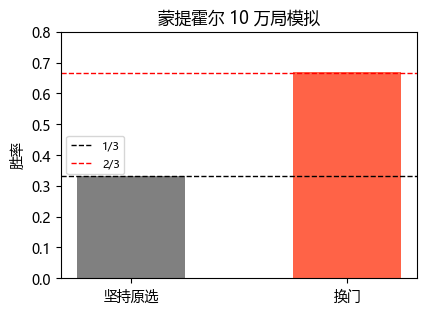

In [10]:
def monty_hall(switch, trials=100_000):
    car  = rng.integers(0, 3, trials)                 # 汽车所在门
    pick = rng.integers(0, 3, trials)                 # 选手初始选择
    opened = (pick + rng.integers(1, 3, trials)) % 3  # 从另外两扇随机开一扇
    opened = np.where(opened == car, 3 - pick - opened, opened)
    #        ↑ 主持人规则：若误开到汽车门，改开另一扇（必为山羊）
    final = np.where(switch, 3 - pick - opened, pick)
    return float(np.mean(final == car))

stay, swap = monty_hall(False), monty_hall(True)
print(f"不换：{stay:.4f}（理论 1/3 = {1/3:.4f}）")
print(f"换：  {swap:.4f}（理论 2/3 = {2/3:.4f}）")
fig, ax = plt.subplots(figsize=(4.6, 3.2))
bars = ax.bar(["坚持原选", "换门"], [stay, swap], color=["gray", "tomato"], width=0.5)
ax.axhline(1/3, color="k", ls="--", lw=1, label="1/3")
ax.axhline(2/3, color="r", ls="--", lw=1, label="2/3")
ax.set_ylim(0, 0.8); ax.set_ylabel("胜率"); ax.legend(fontsize=8)
ax.set_title("蒙提霍尔 10 万局模拟")
save(fig, "out-1-8.png"); plt.show()

## 实验 6 优惠券收集（S&M §1.4）

集齐 $n$ 种等可能优惠券平均要 $nH_n$ 包（推导见笔记 §1.6）。模拟 2000 次。

模拟均值 = 29.07，理论 n·H_n = 29.29


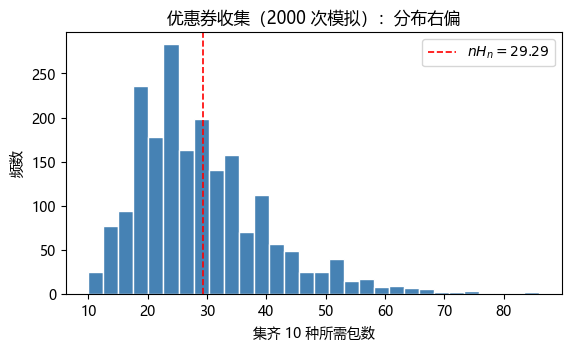

In [11]:
n, trials = 10, 2000
counts = np.empty(trials, dtype=int)
for t in range(trials):
    seen, d = set(), 0
    while len(seen) < n:
        seen.add(int(rng.integers(n)))
        d += 1
    counts[t] = d
Hn = float(np.sum(1 / np.arange(1, n + 1)))
print(f"模拟均值 = {counts.mean():.2f}，理论 n·H_n = {n*Hn:.2f}")
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.hist(counts, bins=30, color="steelblue", edgecolor="white")
ax.axvline(n*Hn, color="r", ls="--", lw=1.2, label=f"$nH_n={n*Hn:.2f}$")
ax.set_xlabel("集齐 10 种所需包数"); ax.set_ylabel("频数")
ax.legend(); ax.set_title("优惠券收集（2000 次模拟）：分布右偏")
save(fig, "out-1-9.png"); plt.show()

## 实验 7 洗牌：正确的与错误的算法（S&M §1.4 / 习题 22）

**Fisher–Yates**：第 $i$ 步从 $[i, n)$ 等可能选 $j$ 交换 → 所有排列等可能。**错误版**：每步都从 $[0, n)$ 全范围选 $j$ → 偏向某些排列。检验：看"编号 0 的牌最终落位"是否均匀。

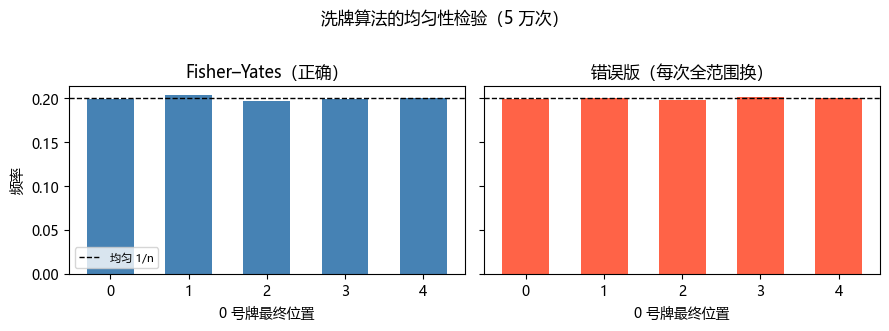

In [12]:
def shuffle(perm, biased=False):
    n = len(perm)
    for i in range(n):
        j = int(rng.integers(0, n)) if biased else int(rng.integers(i, n))
        perm[i], perm[j] = perm[j], perm[i]
    return perm

n, shuffles = 5, 50_000
final = np.empty((2, shuffles), dtype=int)   # 两法各自"0 号牌最终位置"
for s in range(shuffles):
    final[0, s] = shuffle(list(range(n))).index(0)
    final[1, s] = shuffle(list(range(n)), biased=True).index(0)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for k, (title, c) in enumerate([("Fisher–Yates（正确）", "steelblue"), ("错误版（每次全范围换）", "tomato")]):
    ax[k].bar(np.arange(n), np.bincount(final[k], minlength=n)/shuffles, color=c, width=0.6)
    ax[k].axhline(1/n, color="k", ls="--", lw=1, label="均匀 1/n")
    ax[k].set_title(title); ax[k].set_xlabel("0 号牌最终位置")
ax[0].set_ylabel("频率"); ax[0].legend(fontsize=8)
fig.suptitle("洗牌算法的均匀性检验（5 万次）", y=1.02)
fig.tight_layout(); save(fig, "out-1-10.png"); plt.show()